<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-2/Laboratorios/Laboratorio_12_Lab_Hopfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def patrones_balanceados(n, m):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

def agregar_ruido(s, frac=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

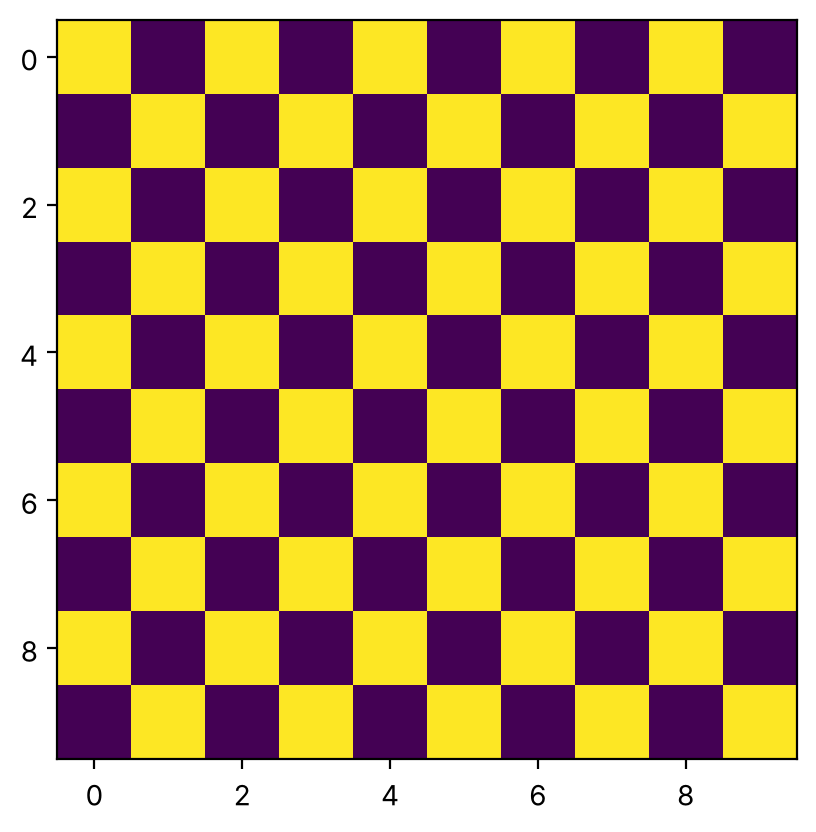

In [ ]:
h, v, d = patrones_balanceados(10, 10)
plt.imshow(d)

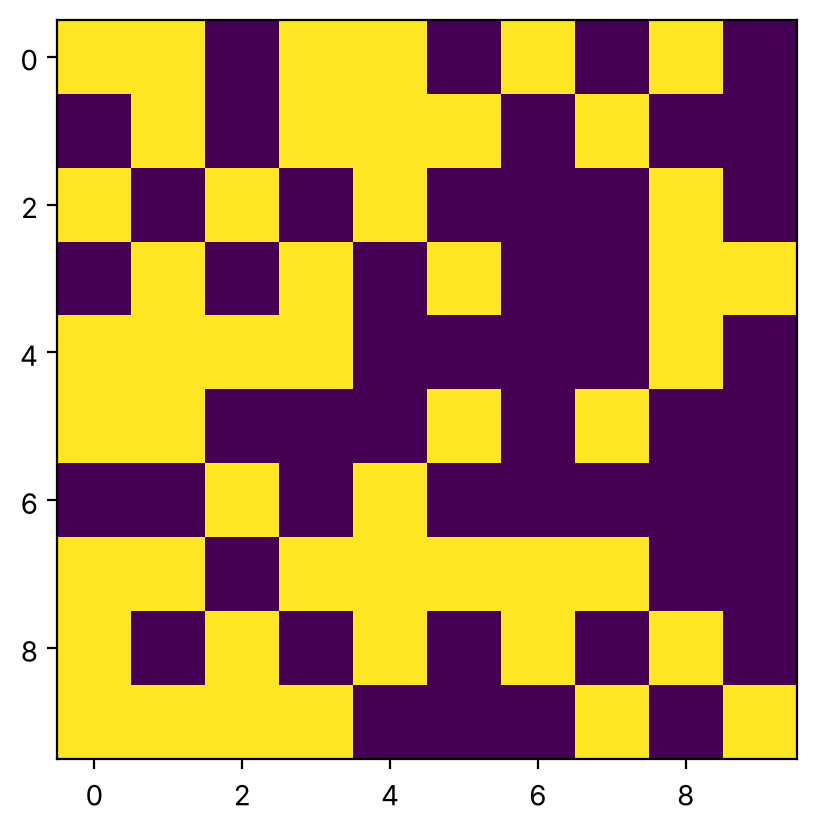

In [ ]:
s_ruido = agregar_ruido(np.concat(d), frac=0.25, seed=10)
plt.imshow(np.reshape(s_ruido, (10, 10)))

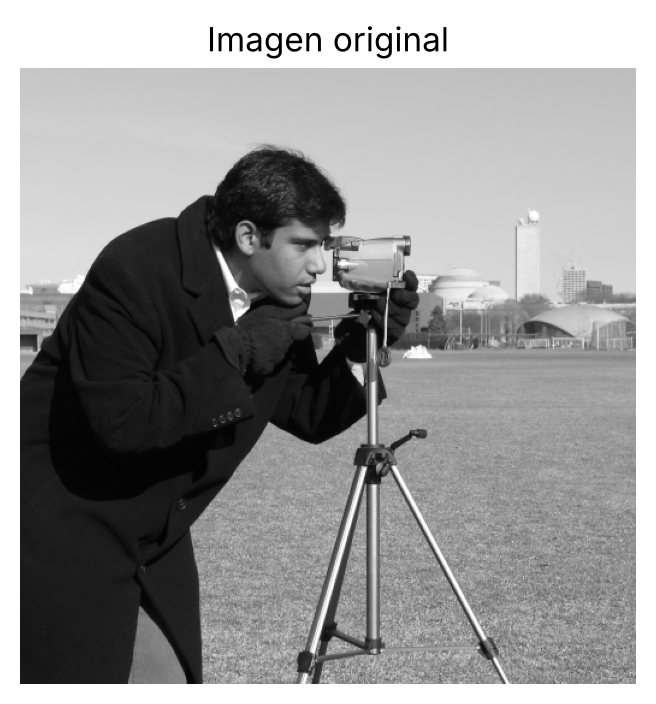

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

img = data.camera()   # imagen 512x512 en escala de grises

plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

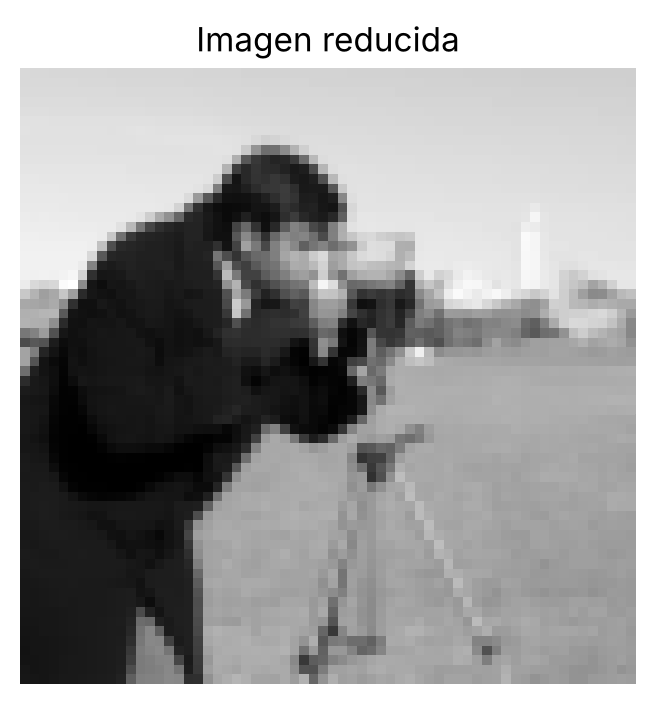

In [ ]:
# ============================================================
# Reducir imagen
# ============================================================

n = 64
m = 64

img_small = resize(img, (n, m), anti_aliasing=True)

plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()

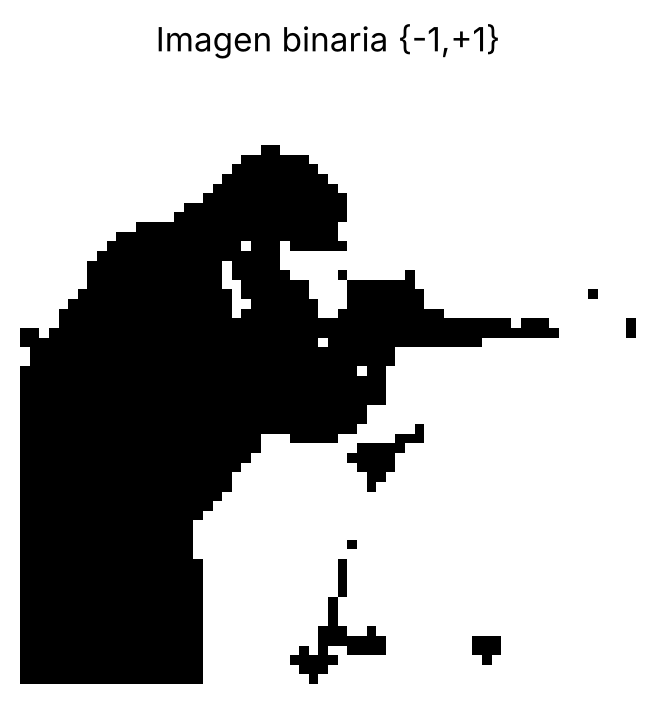

In [ ]:
# ============================================================
# Binarización
# ============================================================

threshold = img_small.mean()

img_bin = np.where(img_small > threshold, 1, -1)

plt.figure(figsize=(4,4))
plt.imshow(img_bin, cmap="gray")
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

In [ ]:
img_bin

array([[ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       ...,
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1]], shape=(64, 64))

In [ ]:
# ============================================================
# Ruido
# ============================================================

def agregar_ruido(s, frac=0.30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido


frac_ruido = 0.30

s_ruido = agregar_ruido(np.concat(img_bin), frac=frac_ruido, seed=123)


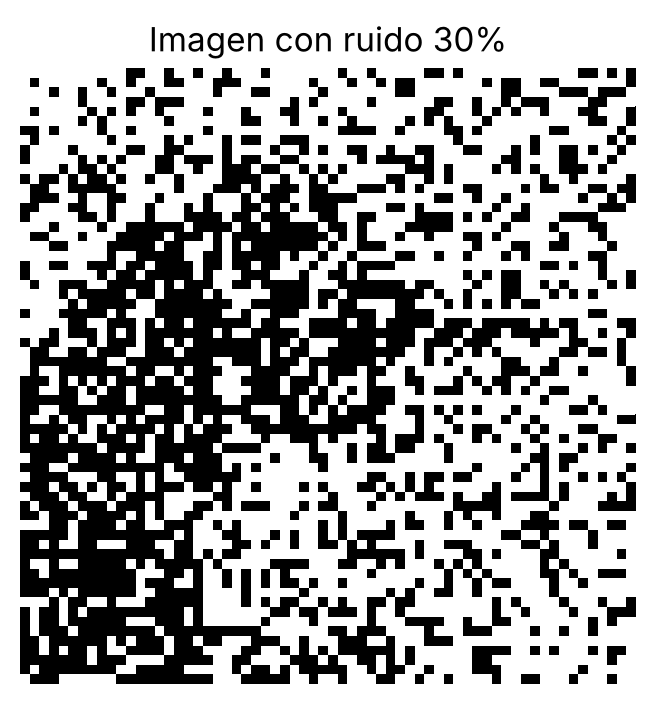

In [ ]:
plt.figure(figsize=(4,4))
plt.imshow(s_ruido.reshape(n, m), cmap="gray")
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()

# Solución

In [ ]:
#Librerias
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

# 1. Funciones de la red
Implementamos las funciones. Primero pasamos la imagen a un vector de estados $\pm1$ y calculamos la matriz de pesos con la regla de Hebb. Si ponemos los patrones como filas de una matriz $X$, la suma sobre los patrones es el producto `X.T @ X`, así no hay que hacer todos los ciclos.

In [ ]:
def imagen_a_vector(img):
    return np.array(img, dtype=float).flatten()


def matriz_pesos(patrones):
    X = np.array([imagen_a_vector(p) for p in patrones])   # un patrón por fila
    N = X.shape[1]
    W = X.T @ X / N
    np.fill_diagonal(W, 0)
    return W

El campo local de la neurona $i$ es la fila $i$ de la matriz de pesos por el estado actual. Si el campo es positivo la neurona queda en 1, si es negativo en -1 y si es cero la dejamos como estaba.

In [ ]:
def campo_local(W, s, i):
    return W[i] @ s


def actualizar(s_i, h_i):
    if h_i > 0:
        return 1.0
    if h_i < 0:
        return -1.0
    return s_i


def energia(W, s):
    return -0.5 * s @ W @ s

Para la recuperación visitamos todos los píxeles en un orden aleatorio, haciendo un barrido y repetimos barridos hasta que en uno completo no cambie ningún píxel. En ese punto la imagen ya no se va a mover más.

Calcular la energía completa después de cada píxel es muy lento entonces solo sumamos lo que cambia al voltear un píxel, que sale del mismo campo local que ya calculamos.

In [ ]:
def recuperar(W, s_inicial, max_barridos=50, seed=0, aleatorio=True):
    rng = np.random.default_rng(seed)
    s = np.array(s_inicial, dtype=float)
    N = len(s)
    E = energia(W, s)
    energias = [E]

    for barrido in range(max_barridos):
        if aleatorio:
            orden = rng.permutation(N)
        else:
            orden = np.arange(N)

        cambios = 0
        for i in orden:
            h = campo_local(W, s, i)
            nuevo = actualizar(s[i], h)
            if nuevo != s[i]:
                E = E + 2 * s[i] * h   # cambio de energía al voltear el píxel i
                s[i] = nuevo
                cambios += 1
            energias.append(E)

        if cambios == 0:
            break

    return s, energias

Para comparar el estado de la red con un patrón usamos el parecido, que es el promedio de $s_i \xi_i$. Vale 1 si son iguales, 0 si no tienen nada que ver y -1 si uno es el negativo del otro.

In [ ]:
def parecido(s, patron):
    return s @ patron / len(patron)

# 2. Recuperación de la imagen

Empecemos con el tablero de ajedrez antes de hacerlo con el camarografo, Guardamos los tres y recuperamos el tablero con el mismo ruido de antes, 25 % con una `seed=10`.

In [ ]:
Wb = matriz_pesos([h, v, d])
d_vec = imagen_a_vector(d)

d_ruido = agregar_ruido(d_vec, frac=0.25, seed=10)
d_rec, E_d = recuperar(Wb, d_ruido)

print("Píxeles distintos antes =", np.sum(d_ruido != d_vec))
print("Píxeles distintos después =", np.sum(d_rec != d_vec))

Píxeles distintos antes = 25
Píxeles distintos después = 0


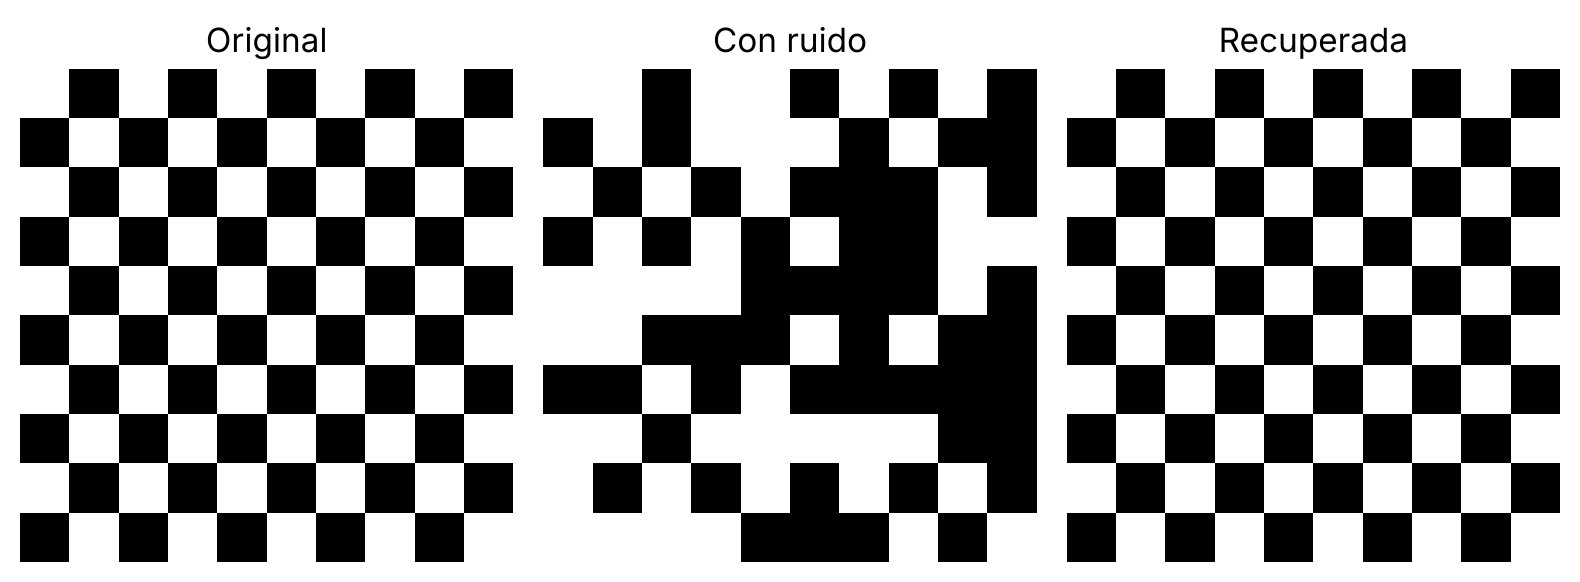

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(8, 3))
ejes[0].imshow(d, cmap="gray")
ejes[0].set_title("Original")
ejes[1].imshow(d_ruido.reshape(10, 10), cmap="gray")
ejes[1].set_title("Con ruido")
ejes[2].imshow(d_rec.reshape(10, 10), cmap="gray")
ejes[2].set_title("Recuperada")
for ax in ejes:
    ax.axis("off")
plt.tight_layout()
plt.show()

La red recupera el tablero sin errores. Los tres patrones son muy distintos entre sí.


Ahora guardamos la imagen binaria de 64×64 y partimos de la versión con 30 % de ruido que se construyó antes

In [ ]:
xi = imagen_a_vector(img_bin)
W = matriz_pesos([img_bin])

s_rec, E_rec = recuperar(W, s_ruido)

print("Píxeles distintos antes =", np.sum(s_ruido != xi))
print("Píxeles distintos después =", np.sum(s_rec != xi))
print("Energía inicial =", round(E_rec[0], 1))
print("Energía final =", round(E_rec[-1], 1))
print("Energía calculada directamente al final =", round(energia(W, s_rec), 1))

Píxeles distintos antes = 1228
Píxeles distintos después = 0
Energía inicial = -327.8
Energía final = -2047.5
Energía calculada directamente al final = -2047.5


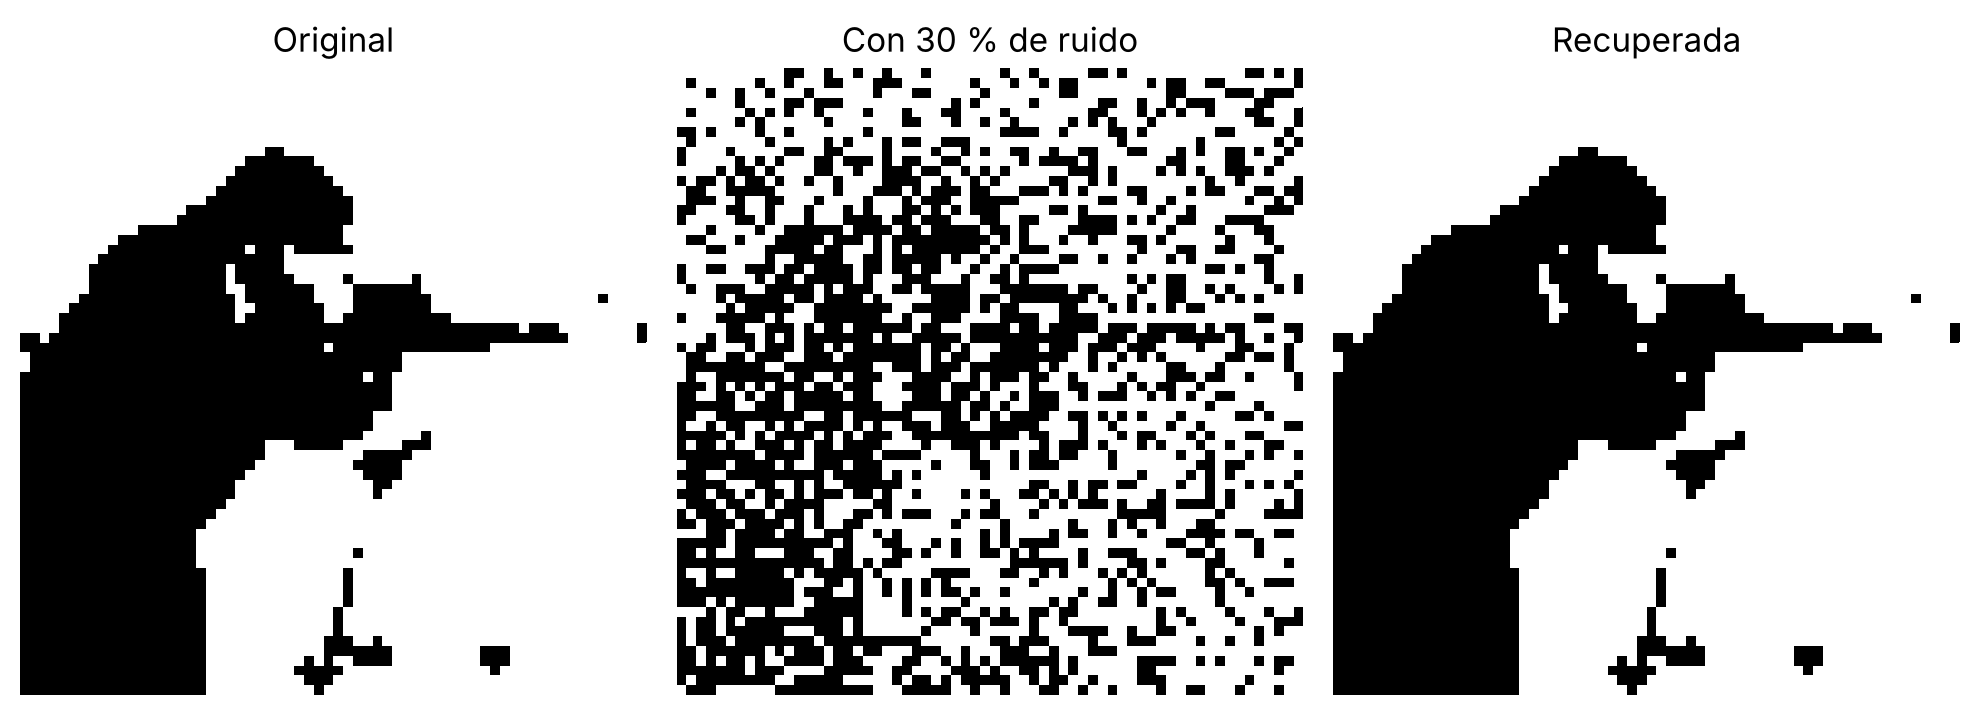

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(10, 3.5))
ejes[0].imshow(img_bin, cmap="gray")
ejes[0].set_title("Original")
ejes[1].imshow(s_ruido.reshape(n, m), cmap="gray")
ejes[1].set_title("Con 30 % de ruido")
ejes[2].imshow(s_rec.reshape(n, m), cmap="gray")
ejes[2].set_title("Recuperada")
for ax in ejes:
    ax.axis("off")
plt.tight_layout()
plt.show()

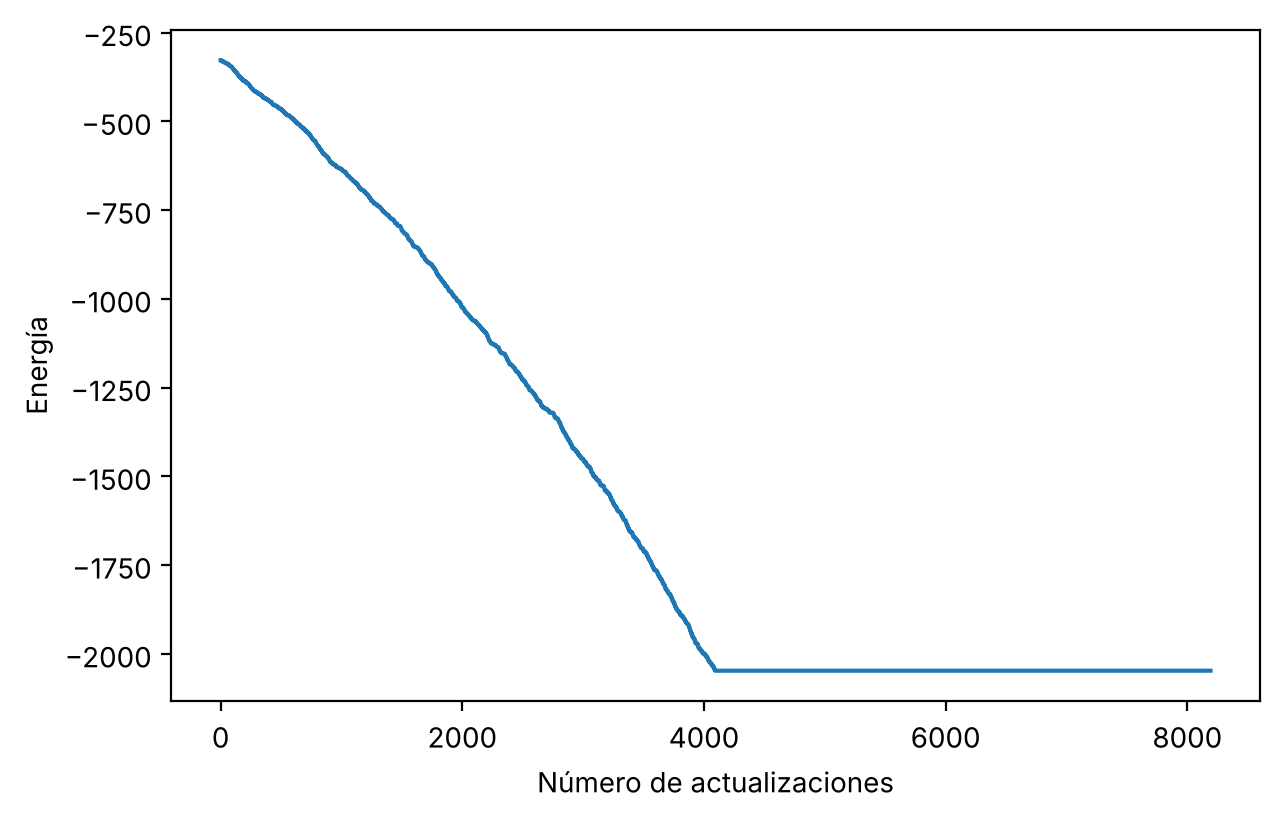

In [ ]:
plt.figure(figsize=(6.5, 4.2))
plt.plot(E_rec)
plt.xlabel("Número de actualizaciones")
plt.ylabel("Energía")
plt.tight_layout()
plt.show()

### Análisis
La red recupera la imagen completa, los 1228 píxeles que había volteado el ruido vuelven a su valor original. La energía baja durante todo el primer barrido y después queda plana, porque la red ya llegó a la imagen original y ningún píxel quiere cambiar. El segundo barrido solo confirma eso. La energía que vamos sumando paso a paso coincide con la que se calcula directamente al final, así que el atajo funciona.

Con una sola imagen guardada el problema es fácil para la red. Cada píxel se fija en si el resto de la imagen se parece más a la original o a su negativo, y con 30 % de ruido todavía se parece mucho más a la original.

# Preguntas guía
## 1. Nivel de ruido
Repetimos la recuperación aumentando el ruido.

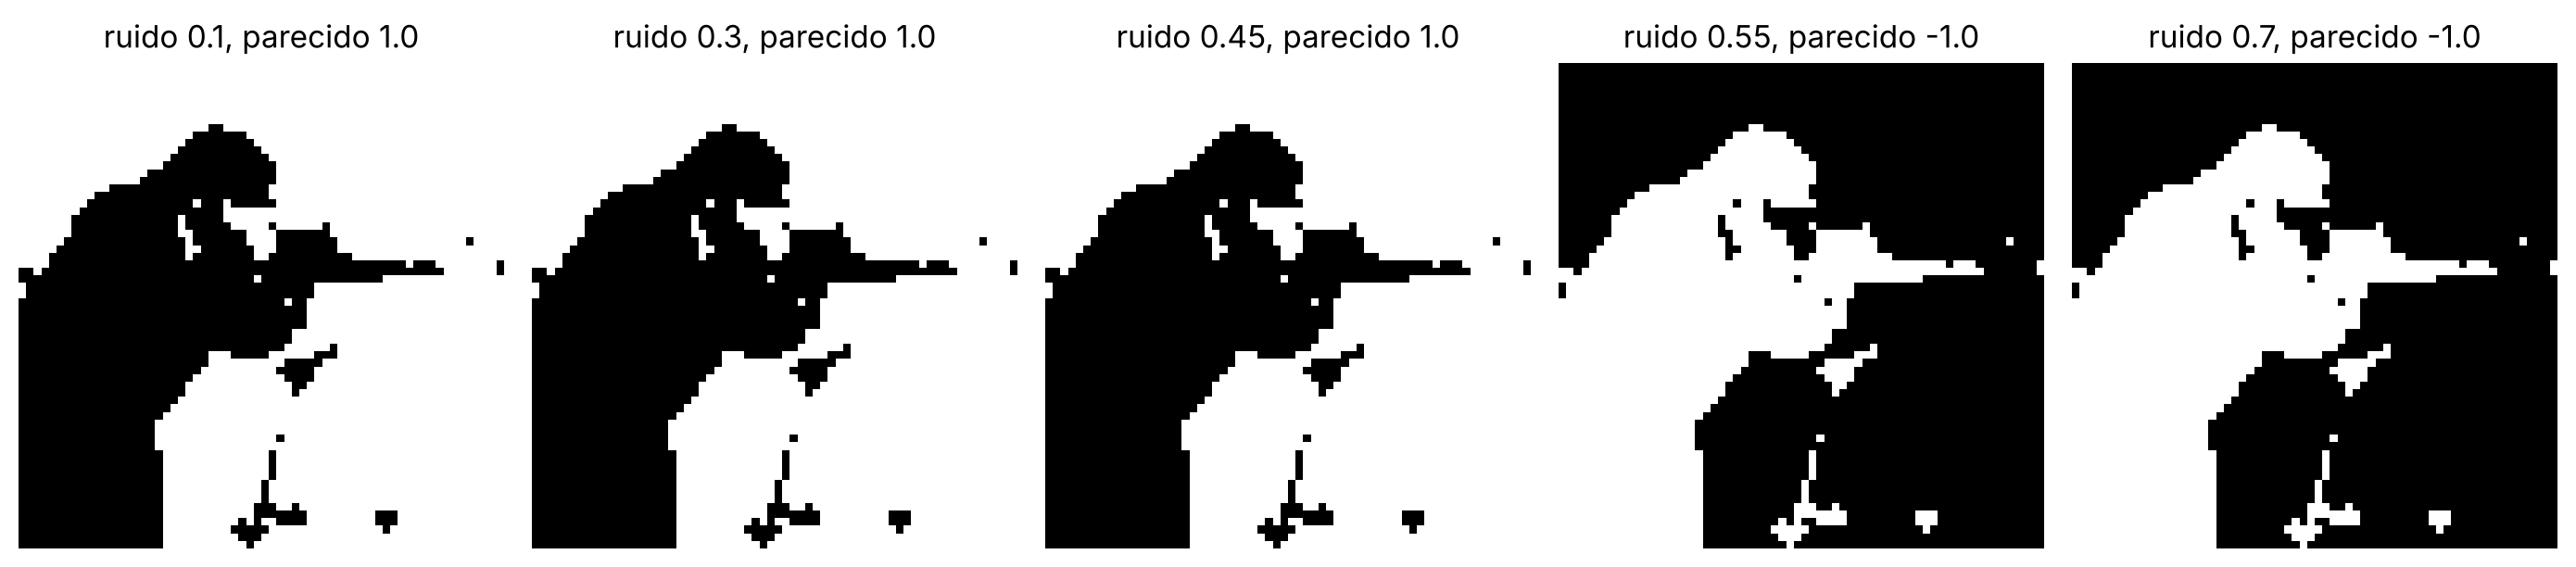

In [ ]:
ruidos = [0.1, 0.3, 0.45, 0.55, 0.7]

fig, ejes = plt.subplots(1, len(ruidos), figsize=(14, 3.2))

for i in range(len(ruidos)):
    s0 = agregar_ruido(xi, frac=ruidos[i], seed=1)
    s_f, E_f = recuperar(W, s0)

    ejes[i].imshow(s_f.reshape(n, m), cmap="gray")
    ejes[i].set_title("ruido " + str(ruidos[i]) + ", parecido " + str(round(parecido(s_f, xi), 2)))
    ejes[i].axis("off")

plt.tight_layout()
plt.show()

### Análisis
Mientras el ruido no pase de la mitad de los píxeles la red recupera la imagen perfecta, así sea con 45 %. Cuando el ruido pasa de 50 % la red termina en negativo, con el blanco y el negro invertidos. Una imagen con más de la mitad de píxeles volteados ya se parece más al negativo que a la original, y para la red el negativo es igual de bueno porque tiene la misma energía.

## 2. Varias imágenes y estados espurios
Tomamos otras imágenes de `skimage` y las pasamos a 64×64, Las guardamos una por una y siempre intentamos recuperar el camarógrafo desde la misma imagen con un 30 % de ruido.

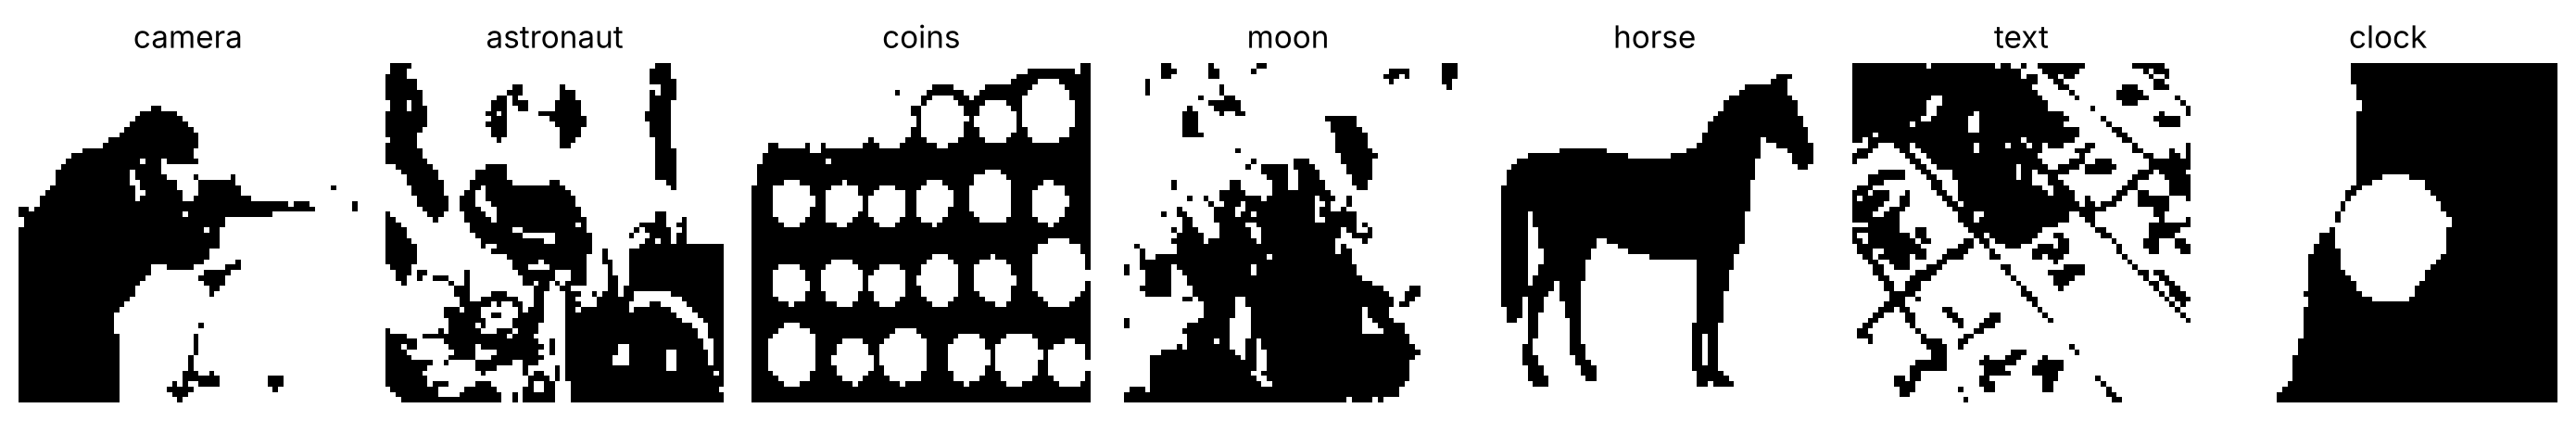

In [ ]:
def binarizar(img):
    if img.ndim == 3:
        img = rgb2gray(img)
    pequena = resize(img.astype(float), (n, m), anti_aliasing=True)
    return np.where(pequena > pequena.mean(), 1, -1)


nombres = ["camera", "astronaut", "coins", "moon", "horse", "text", "clock"]
banco = [binarizar(getattr(data, nombre)()) for nombre in nombres]

fig, ejes = plt.subplots(1, 7, figsize=(14, 2.6))
for i in range(7):
    ejes[i].imshow(banco[i], cmap="gray")
    ejes[i].set_title(nombres[i])
    ejes[i].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
resultados = []

for k in range(1, 8):
    Wk = matriz_pesos(banco[:k])
    s_k, E_k = recuperar(Wk, s_ruido)
    resultados.append(s_k)
    print("Imágenes guardadas =", k, "  parecido con el camarógrafo =", round(parecido(s_k, xi), 2))

Imágenes guardadas = 1   parecido con el camarógrafo = 1.0
Imágenes guardadas = 2   parecido con el camarógrafo = 1.0


Imágenes guardadas = 3   parecido con el camarógrafo = 1.0
Imágenes guardadas = 4   parecido con el camarógrafo = 1.0


Imágenes guardadas = 5   parecido con el camarógrafo = 1.0
Imágenes guardadas = 6   parecido con el camarógrafo = 1.0


Imágenes guardadas = 7   parecido con el camarógrafo = 0.86


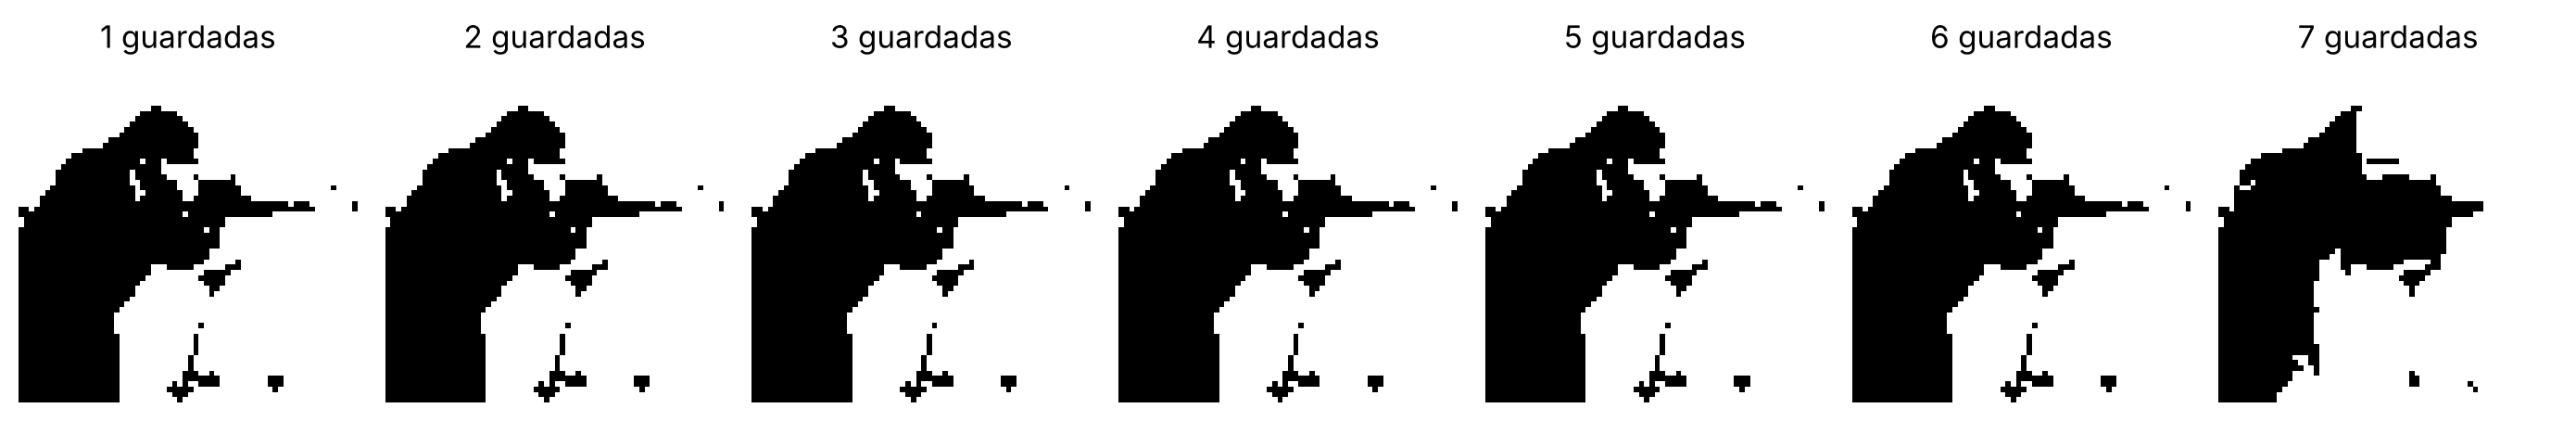

In [ ]:
fig, ejes = plt.subplots(1, 7, figsize=(14, 2.6))
for i in range(7):
    ejes[i].imshow(resultados[i].reshape(n, m), cmap="gray")
    ejes[i].set_title(str(i + 1) + " guardadas")
    ejes[i].axis("off")
plt.tight_layout()
plt.show()

Con 7 imágenes la red ya no llega al camarógrafo. Miramos a qué se parece el estado final y comparamos su energía con la del camarógrafo.

In [ ]:
W7 = matriz_pesos(banco)
espurio = resultados[6]

for i in range(7):
    print("Parecido con", nombres[i], "=", round(parecido(espurio, imagen_a_vector(banco[i])), 2))

print()
print("Energía del estado final =", round(energia(W7, espurio), 1))
print("Energía del camarógrafo =", round(energia(W7, xi), 1))

Parecido con camera = 0.86
Parecido con astronaut = 0.05
Parecido con coins = 0.11
Parecido con moon = 0.16
Parecido con horse = 0.54
Parecido con text = 0.2
Parecido con clock = -0.69

Energía del estado final = -3243.9
Energía del camarógrafo = -3122.5


### Análisis
Hasta 6 imágenes guardadas la recuperación sigue siendo perfecta. Al guardar la séptima imagen que es el reloj, la red termina en una imagen parecida al camarógrafo pero con varias zonas mal. Ese estado final no es ninguna de las imágenes guardadas. Se parece al camarógrafo, pero también tiene algo del caballo y del negativo del reloj, es una mezcla de las diferentes cofiguranciones. Además tiene menos energía que el propio camarógrafo, así que para la red es un mínimo mejor que la imagen que queríamos. Ese es un estado espurio. El negativo que salió en la parte de ruido también es un estado que no se guardo.

La fórmula de capacidad dice que con 4096 neuronas se podrían guardar unas 565 imágenes, y aquí falla con 7. Creemos que el problema es que el reloj se parece bastante al negativo del camarógrafo (-0.55) y no la cantidad de imágenes. La fórmula supone imágenes aleatorias que no se parecen entre sí y en este caso las fotos reales sí se parecen.

https://www.ibm.com/mx-es/think/topics/ai-bias

## 3. Orden de actualización
Usamos la red con 6 imágenes y repetimos la recuperación con varios órdenes aleatorios y con el orden en fila, píxel 0, 1, 2 y así. Lo hacemos con 30 % y con 48 % de ruido.

In [ ]:
W6 = matriz_pesos(banco[:6])

for f in [0.30, 0.48]:
    s0 = agregar_ruido(xi, frac=f, seed=7)
    print("Ruido =", f)

    for semilla in range(5):
        s_o, E_o = recuperar(W6, s0, seed=semilla)
        print("   orden aleatorio", semilla, "  parecido =", round(parecido(s_o, xi), 2))

    s_o, E_o = recuperar(W6, s0, aleatorio=False)
    print("   orden en fila   parecido =", round(parecido(s_o, xi), 2))

Ruido = 0.3
   orden aleatorio 0   parecido = 1.0


   orden aleatorio 1   parecido = 1.0
   orden aleatorio 2   parecido = 1.0
   orden aleatorio 3   parecido = 1.0
   orden aleatorio 4   parecido = 1.0
   orden en fila   parecido = 1.0
Ruido = 0.48


   orden aleatorio 0   parecido = 0.82
   orden aleatorio 1   parecido = 0.82


   orden aleatorio 2   parecido = 1.0
   orden aleatorio 3   parecido = 0.82
   orden aleatorio 4   parecido = 1.0
   orden en fila   parecido = 0.7


### Análisis
Con 30 % de ruido el orden no importa y todos llegan a la imagen original. Con 48 % sí cambia, algunos órdenes llegan a la original y otros se quedan en estados intermedios. Cuando la imagen está tan dañada queda casi en la frontera entre ir hacia la original o hacia otro mínimo, y los primeros píxeles que se actualizan terminan decidiendo para dónde se va.

## 4. Actualización sincrónica y asincrónica
En la sincrónica todos los píxeles se actualizan al mismo tiempo usando la imagen del paso anterior. Paramos si la imagen no cambia o si vuelve a la de dos pasos atrás lo que quiere decir que quedó saltando entre dos imágenes.

In [ ]:
def recuperar_sincrono(W, s_inicial, max_pasos=50):
    s = np.array(s_inicial, dtype=float)1
    anterior = s.copy()

    for paso in range(max_pasos):
        h = W @ s
        nuevo = np.where(h > 0, 1.0, np.where(h < 0, -1.0, s))

        if np.array_equal(nuevo, s):
            return s, "se quedó quieta"
        if paso > 0 and np.array_equal(nuevo, anterior):
            return s, "quedó saltando entre dos imágenes"

        anterior = s
        s = nuevo

    return s, 'no paró'

In [ ]:
s_sin, estado = recuperar_sincrono(W, s_ruido)
print("Camarógrafo, sincrónica", estado, "con", np.sum(s_sin != xi), "píxeles distintos")

d_ruido2 = agregar_ruido(d_vec, frac=0.5, seed=4)
s_sin, estado = recuperar_sincrono(Wb, d_ruido2)
s_asin, E_asin = recuperar(Wb, d_ruido2)
print("Tablero con 50 % de ruido, sincrónica", estado)

Camarógrafo, sincrónica se quedó quieta con 0 píxeles distintos
Tablero con 50 % de ruido, sincrónica quedó saltando entre dos imágenes


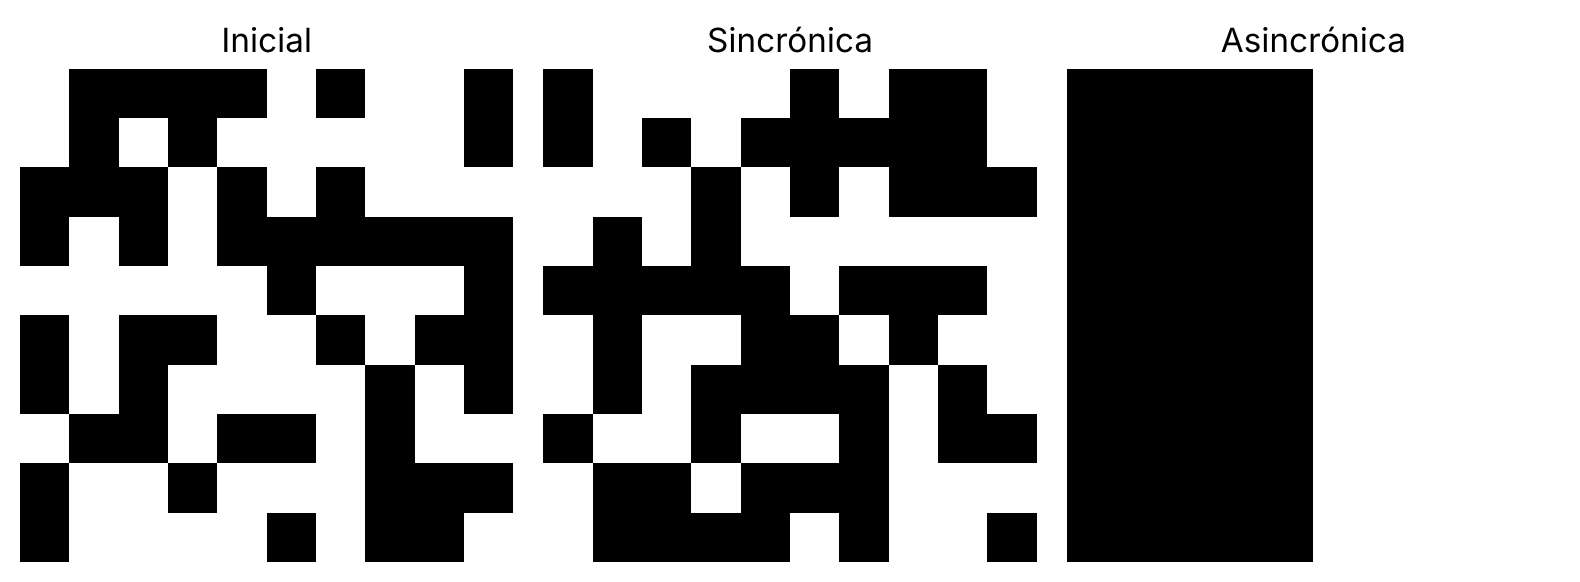

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(8, 3))
ejes[0].imshow(d_ruido2.reshape(10, 10), cmap="gray")
ejes[0].set_title("Inicial")
ejes[1].imshow(s_sin.reshape(10, 10), cmap="gray")
ejes[1].set_title("Sincrónica")
ejes[2].imshow(s_asin.reshape(10, 10), cmap="gray")
ejes[2].set_title("Asincrónica")
for ax in ejes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Análisis
Con la imagen del camarógrafo las dos formas funcionan bien, con el tablero y 50 % de ruido la sincrónica se queda saltando entre la imagen inicial y la del centro, mientras que la asincrónica sí se queda quieta en un solo patron, el negativo del vertical. En la asincrónica cada cambio de un píxel hace que la energía baje o se quede igual, entonces la red no puede devolverse y tiene que buscar otro minimo para terminar. En la sincrónica cambian muchos píxeles a la vez y cada uno decide sin saber que los demás también están cambiando, por eso puede quedar en un ciclo.

## Conclusiones
. La red de Hopfield recupera la imagen con los parámetros del laboratorio y la energía siempre baja durante la recuperación asincrónica.

. La red funciona bien mientras el ruido no pase de la mitad de los píxeles y mientras las imágenes guardadas no se parezcan mucho entre sí. Con fotos reales el límite llegó mucho antes de lo que dice la fórmula de capacidad, y ahí aparecen estados espurios que son mezclas de varias imágenes.

. La actualización asincrónica es la más confiable porque siempre termina en un estado estable, mientras que la sincrónica puede quedarse en ciclos.